In [ ]:
!pip install cvxpy

Solver Status: optimal
24/7 CFE Match Score: 93.26%
Fossil Grid Imports:  323.3 MWh
Curtailed RE:         484.0 MWh


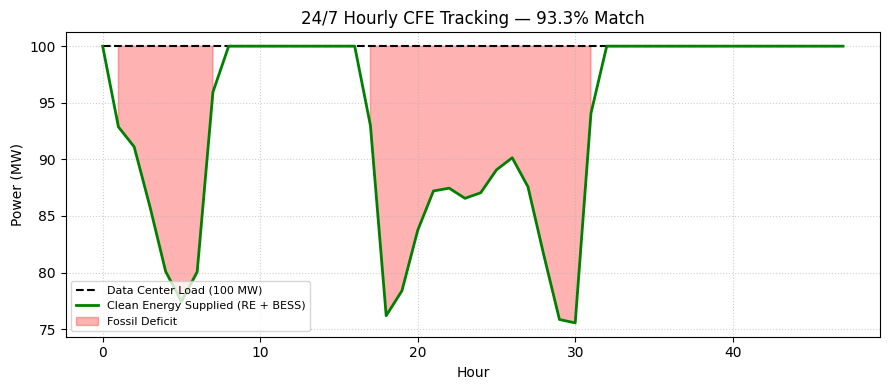

In [ ]:
import cvxpy as cp
import numpy as np
import matplotlib.pyplot as plt

# 1. 48-Hour Synthetic Horizon & 100 MW Data Center Load
hours = 48
time = np.arange(hours)
load_mw = np.full(hours, 100.0)

# Synthetic Renewables: Solar (midday peak) & Wind (night-heavy)
solar_norm = np.maximum(0, np.sin((time % 24 - 6) * np.pi / 12))
wind_norm = np.clip(0.4 + 0.3 * np.cos((time % 24) * np.pi / 12) + 0.05 * np.sin(time), 0, 1)

total_re = (180.0 * solar_norm) + (120.0 * wind_norm)  # 180MW Solar + 120MW Wind

# 2. Battery Storage (BESS) Specs
bess_power = 60.0    # 60 MW inverter rating
bess_energy = 240.0  # 240 MWh capacity (4-hour duration)
eta = 0.90           # 90% single-trip efficiency

# 3. Decision Variables
p_chg  = cp.Variable(hours, nonneg=True)
p_dis  = cp.Variable(hours, nonneg=True)
soc    = cp.Variable(hours, nonneg=True)
p_grid = cp.Variable(hours, nonneg=True)
p_curt = cp.Variable(hours, nonneg=True)

# 4. Physical Constraints
constraints = [
    soc[0] == 0.5 * bess_energy,
    p_chg <= bess_power,
    p_dis <= bess_power,
    soc <= bess_energy
]

for t in range(hours):
    # Hourly energy balance at data center bus
    constraints.append(total_re[t] + p_dis[t] + p_grid[t] == load_mw[t] + p_chg[t] + p_curt[t])
    if t > 0:
        constraints.append(soc[t] == soc[t-1] + eta * p_chg[t] - (1.0 / eta) * p_dis[t])

# 5. Objective: Minimize fossil grid import + curtailment penalty
prob = cp.Problem(cp.Minimize(cp.sum(80.0 * p_grid + 10.0 * p_curt)), constraints)
prob.solve()

# 6. Metrics & Plotting
grid_used = p_grid.value
clean_delivered = load_mw - grid_used
cfe_score = (np.sum(clean_delivered) / np.sum(load_mw)) * 100.0

print(f"Solver Status: {prob.status}")
print(f"24/7 CFE Match Score: {cfe_score:.2f}%")
print(f"Fossil Grid Imports:  {np.sum(grid_used):.1f} MWh")
print(f"Curtailed RE:         {np.sum(p_curt.value):.1f} MWh")

# Visual chart
plt.figure(figsize=(9, 4))
plt.plot(time, load_mw, 'k--', label='Data Center Load (100 MW)')
plt.plot(time, clean_delivered, 'g-', label='Clean Energy Supplied (RE + BESS)', linewidth=2)
plt.fill_between(time, clean_delivered, load_mw, where=(clean_delivered < load_mw),
                 color='red', alpha=0.3, label='Fossil Deficit')
plt.xlabel('Hour')
plt.ylabel('Power (MW)')
plt.title(f'24/7 Hourly CFE Tracking — {cfe_score:.1f}% Match')
plt.legend(loc='lower left', fontsize=8)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
# Battery Capacity Sensitivity Sweep (0h to 8h storage)
storage_durations = [0, 2, 4, 6, 8]  # hours of storage at 60 MW rating
cfe_results = []
curtailment_results = []

for dur in storage_durations:
    e_cap = max(1e-3, 60.0 * dur)
    p_cap = 60.0 if dur > 0 else 1e-3

    p_c = cp.Variable(hours, nonneg=True)
    p_d = cp.Variable(hours, nonneg=True)
    s = cp.Variable(hours, nonneg=True)
    p_g = cp.Variable(hours, nonneg=True)
    p_w = cp.Variable(hours, nonneg=True)

    cons = [s[0] == 0.5 * e_cap, p_c <= p_cap, p_d <= p_cap, s <= e_cap]
    for t in range(hours):
        cons.append(total_re[t] + p_d[t] + p_g[t] == load_mw[t] + p_c[t] + p_w[t])
        if t > 0:
            cons.append(s[t] == s[t-1] + eta * p_c[t] - (1.0 / eta) * p_d[t])

    prob_sweep = cp.Problem(cp.Minimize(cp.sum(80.0 * p_g + 10.0 * p_w)), cons)
    prob_sweep.solve()

    delivered = load_mw - p_g.value
    cfe_results.append((np.sum(delivered) / np.sum(load_mw)) * 100.0)
    curtailment_results.append(np.sum(p_w.value))

# Print summary table
print("Duration (hrs) | Capacity (MWh) | CFE Match (%) | Curtailed (MWh)")
print("-" * 58)
for d, cfe, curt in zip(storage_durations, cfe_results, curtailment_results):
    print(f"{d:^14} | {d*60:^14} | {cfe:^13.1f}% | {curt:^15.1f}")

Duration (hrs) | Capacity (MWh) | CFE Match (%) | Curtailed (MWh)
----------------------------------------------------------
      0        |       0        |     81.8     % |     1121.2     
      2        |      120       |     87.8     % |      700.0     
      4        |      240       |     93.3     % |      484.0     
      6        |      360       |     96.6     % |      268.0     
      8        |      480       |     98.6     % |      211.8     


# 3. Production Model with Real Satellite Irradiance (pvlib)

In [ ]:
!pip install pvlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 58.8 MB/s eta 0:00:00


Pune_radiance

Fetching satellite TMY irradiance data from PVGIS...
Solver Status:          optimal
24/7 CFE Match Score:   50.04%
Total Grid Deficit:     8443.0 MWh
Curtailed Solar Energy: 3019.4 MWh


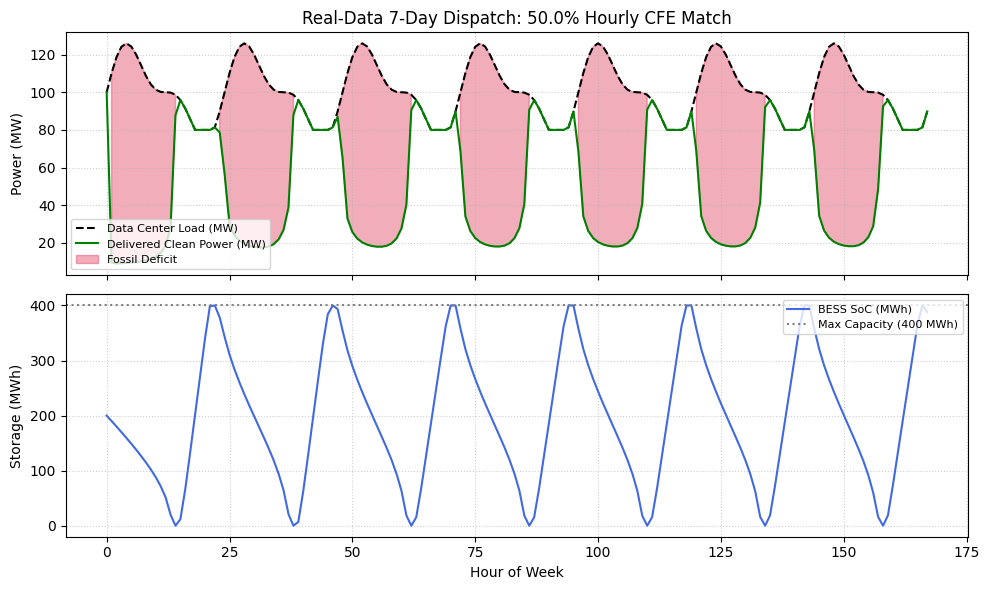

In [ ]:
import cvxpy as cp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pvlib

# ---------------------------------------------------------------------------
# 1. INGEST REAL SATELLITE SOLAR DATA (PVGIS API via pvlib)
# ---------------------------------------------------------------------------
print("Fetching satellite TMY irradiance data from PVGIS...")
# get_pvgis_tmy returns (data, meta)
weather_data = pvlib.iotools.get_pvgis_tmy(latitude=18.52, longitude=73.86)[0]

# Extract a 7-day representative summer sequence (168 consecutive hours)
sample_window = weather_data.iloc[2100:2268].copy().reset_index(drop=True)
n_hours = len(sample_window)
time = np.arange(n_hours)

# Extract Global Horizontal Irradiance (G(h) or ghi)
ghi_col = 'ghi' if 'ghi' in sample_window.columns else 'G(h)'
ghi = sample_window[ghi_col].values

# Convert irradiance to normalized generation (W/m^2 to per-unit rating)
# Standard test condition (STC) reference: 1000 W/m^2
solar_pu = np.clip(ghi / 1000.0, 0, 1.0)

# Fleet Sizing: 250 MW Solar PV Plant
solar_cap_mw = 250.0
solar_gen = solar_cap_mw * solar_pu

# ---------------------------------------------------------------------------
# 2. DYNAMIC HYPERSCALE LOAD PROFILE (100 MW Baseload + AI Workload Bursts)
# ---------------------------------------------------------------------------
# Baseload server cooling + IT compute with variable daytime user batch jobs
base_mw = 100.0
ai_burst = 20.0 * np.sin(time * 2 * np.pi / 24) + 10.0 * np.sin(time * 2 * np.pi / 12)
load_mw = np.maximum(80.0, base_mw + ai_burst)

# ---------------------------------------------------------------------------
# 3. PRODUCTION CFE OPTIMIZATION FUNCTION
# ---------------------------------------------------------------------------
def solve_cfe_dispatch(load, re_gen, bess_mw, bess_mwh, eta=0.90, grid_cost=85.0, curt_penalty=12.0):
    T = len(load)

    # Decision Variables
    p_chg  = cp.Variable(T, nonneg=True)  # Power injected into BESS (MW)
    p_dis  = cp.Variable(T, nonneg=True)  # Power discharged from BESS (MW)
    soc    = cp.Variable(T, nonneg=True)  # Battery State-of-Charge (MWh)
    p_grid = cp.Variable(T, nonneg=True)  # Fossil Grid import (MW)
    p_curt = cp.Variable(T, nonneg=True)  # Curtailed clean power (MW)

    constraints = [
        soc[0] == 0.5 * bess_mwh,       # Initial half-full state
        p_chg <= bess_mw,               # Inverter power rating
        p_dis <= bess_mw,
        soc <= bess_mwh                 # Energy capacity limit
    ]

    for t in range(T):
        # Bus Nodal Energy Balance
        constraints.append(re_gen[t] + p_dis[t] + p_grid[t] == load[t] + p_chg[t] + p_curt[t])

        # State of Charge Dynamics with Round-Trip Loss
        if t > 0:
            constraints.append(soc[t] == soc[t-1] + eta * p_chg[t] - (1.0 / eta) * p_dis[t])

    # Objective: Minimize cost of fossil imports and curtailment losses
    cost_expr = cp.sum(grid_cost * p_grid + curt_penalty * p_curt)
    problem = cp.Problem(cp.Minimize(cost_expr), constraints)
    problem.solve()

    clean_supplied = load - p_grid.value
    match_percentage = (np.sum(clean_supplied) / np.sum(load)) * 100.0

    return {
        "status": problem.status,
        "cfe_score": match_percentage,
        "grid_imports_mwh": np.sum(p_grid.value),
        "curtailed_re_mwh": np.sum(p_curt.value),
        "clean_power": clean_supplied,
        "soc_curve": soc.value
    }

# ---------------------------------------------------------------------------
# 4. EXECUTE & VISUALIZE DISPATCH
# ---------------------------------------------------------------------------
# Test with a 100 MW / 400 MWh BESS (4-hour duration)
sim = solve_cfe_dispatch(load=load_mw, re_gen=solar_gen, bess_mw=100.0, bess_mwh=400.0)

print(f"Solver Status:          {sim['status']}")
print(f"24/7 CFE Match Score:   {sim['cfe_score']:.2f}%")
print(f"Total Grid Deficit:     {sim['grid_imports_mwh']:.1f} MWh")
print(f"Curtailed Solar Energy: {sim['curtailed_re_mwh']:.1f} MWh")

# Visual Dispatch Plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Top Plot: Power Balance
ax1.plot(time, load_mw, 'k--', label='Data Center Load (MW)', linewidth=1.5)
ax1.plot(time, sim['clean_power'], 'g-', label='Delivered Clean Power (MW)', linewidth=1.5)
ax1.fill_between(time, sim['clean_power'], load_mw, where=(sim['clean_power'] < load_mw),
                 color='crimson', alpha=0.35, label='Fossil Deficit')
ax1.set_ylabel('Power (MW)')
ax1.set_title(f'Real-Data 7-Day Dispatch: {sim["cfe_score"]:.1f}% Hourly CFE Match')
ax1.legend(loc='lower left', fontsize=8)
ax1.grid(True, linestyle=':', alpha=0.6)

# Bottom Plot: Battery State-of-Charge (SoC)
ax2.plot(time, sim['soc_curve'], color='royalblue', label='BESS SoC (MWh)', linewidth=1.5)
ax2.axhline(400.0, color='gray', linestyle=':', label='Max Capacity (400 MWh)')
ax2.set_xlabel('Hour of Week')
ax2.set_ylabel('Storage (MWh)')
ax2.legend(loc='upper right', fontsize=8)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

Add Wind Energy (The Solar + Wind + BESS Hybrid)

--- HYBRID PORTFOLIO PERFORMANCE ---
Solar Only Match:    50.04%
Solar + Wind Match:  85.41%
Grid Deficit Drop:   8443.0 MWh -> 2465.4 MWh
Curtailed Energy:    7904.0 MWh


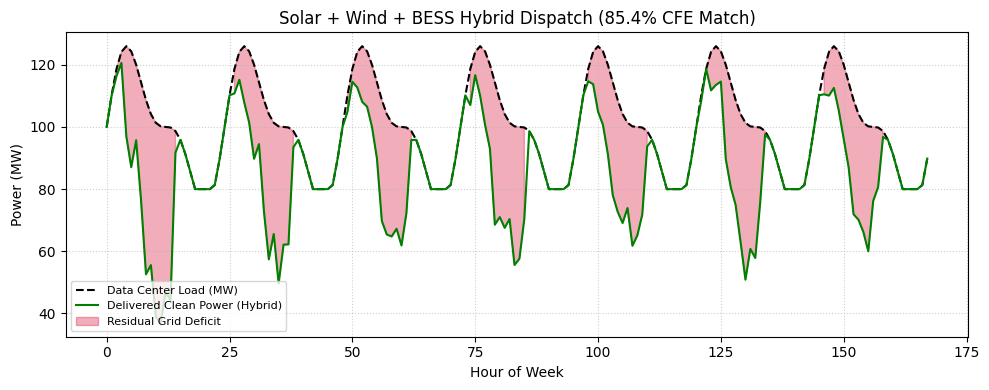

In [ ]:
# ---------------------------------------------------------------------------
# ADD COMPLEMENTARY WIND GENERATION TO THE HYBRID PORTFOLIO
# ---------------------------------------------------------------------------
# Synthetic night-heavy Wind capacity factor profile (higher at night, lower at noon)
np.random.seed(42)
wind_cf = 0.45 + 0.30 * np.cos(time * 2 * np.pi / 24) + 0.08 * np.random.randn(n_hours)
wind_cf = np.clip(wind_cf, 0.05, 0.95)

# Add 150 MW Wind Farm to the existing 250 MW Solar PV Plant
wind_cap_mw = 150.0
wind_gen = wind_cap_mw * wind_cf
hybrid_re_gen = solar_gen + wind_gen

# Re-run the CFE optimization with the Solar + Wind hybrid fleet
hybrid_sim = solve_cfe_dispatch(load=load_mw, re_gen=hybrid_re_gen, bess_mw=100.0, bess_mwh=400.0)

print(f"--- HYBRID PORTFOLIO PERFORMANCE ---")
print(f"Solar Only Match:    {sim['cfe_score']:.2f}%")
print(f"Solar + Wind Match:  {hybrid_sim['cfe_score']:.2f}%")
print(f"Grid Deficit Drop:   {sim['grid_imports_mwh']:.1f} MWh -> {hybrid_sim['grid_imports_mwh']:.1f} MWh")
print(f"Curtailed Energy:    {hybrid_sim['curtailed_re_mwh']:.1f} MWh")

# Visual comparison plot
plt.figure(figsize=(10, 4))
plt.plot(time, load_mw, 'k--', label='Data Center Load (MW)', linewidth=1.5)
plt.plot(time, hybrid_sim['clean_power'], 'g-', label='Delivered Clean Power (Hybrid)', linewidth=1.5)
plt.fill_between(time, hybrid_sim['clean_power'], load_mw,
                 where=(hybrid_sim['clean_power'] < load_mw), color='crimson', alpha=0.35, label='Residual Grid Deficit')
plt.title(f'Solar + Wind + BESS Hybrid Dispatch ({hybrid_sim["cfe_score"]:.1f}% CFE Match)')
plt.xlabel('Hour of Week')
plt.ylabel('Power (MW)')
plt.legend(loc='lower left', fontsize=8)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

The Industry Challenge: "The Last 10–15%"

Asset Co-Optimization (Automated Capacity Sizing)

In [ ]:
# ---------------------------------------------------------------------------
# CO-OPTIMIZATION: SOLVING OPTIMAL FLEET SIZING FOR A TARGET CFE (e.g., 90%)
# ---------------------------------------------------------------------------
target_cfe = 0.90  # 90% strict hourly matching requirement
total_load_mwh = np.sum(load_mw)

# Cost Assumptions (Annualized / Scaled $/MW and $/MWh for a 1-week horizon)
# Capital expenditure amortized per week:
capex_solar_per_mw = 1200.0   # ~$60k/MW-yr
capex_wind_per_mw  = 1600.0   # ~$80k/MW-yr
capex_bess_mwh     = 800.0    # ~$40k/MWh-yr (storage capacity)
capex_bess_mw      = 400.0    # ~$20k/MW-yr (inverter capacity)
grid_buy_cost      = 90.0     # $90/MWh spot import
curt_loss_penalty  = 5.0      # $5/MWh curtailment waste penalty

# SIZING DECISION VARIABLES
cap_solar = cp.Variable(nonneg=True)  # Optimal Solar MW to build
cap_wind  = cp.Variable(nonneg=True)  # Optimal Wind MW to build
cap_b_mw  = cp.Variable(nonneg=True)  # Optimal BESS Inverter MW
cap_b_mwh = cp.Variable(nonneg=True)  # Optimal BESS Energy MWh

# OPERATIONAL DECISION VARIABLES (Hourly)
p_chg_co  = cp.Variable(n_hours, nonneg=True)
p_dis_co  = cp.Variable(n_hours, nonneg=True)
soc_co    = cp.Variable(n_hours, nonneg=True)
p_grid_co = cp.Variable(n_hours, nonneg=True)
p_curt_co = cp.Variable(n_hours, nonneg=True)

# CONSTRAINTS
co_constraints = [
    # Asset Upper Bounds (e.g., land/interconnection limits)
    cap_solar <= 400.0,
    cap_wind  <= 300.0,
    cap_b_mw  <= 200.0,
    cap_b_mwh <= 800.0,

    # Storage Ratings Linkage
    cap_b_mwh >= 2.0 * cap_b_mw,  # Minimum 2-hour storage duration
    soc_co[0] == 0.5 * cap_b_mwh
]

for t in range(n_hours):
    # Available generation at hour t as a function of sized capacity
    gen_t = cap_solar * solar_pu[t] + cap_wind * wind_cf[t]

    # Power Balance
    co_constraints.append(gen_t + p_dis_co[t] + p_grid_co[t] == load_mw[t] + p_chg_co[t] + p_curt_co[t])
    co_constraints.append(p_chg_co[t] <= cap_b_mw)
    co_constraints.append(p_dis_co[t] <= cap_b_mw)
    co_constraints.append(soc_co[t] <= cap_b_mwh)

    if t > 0:
        co_constraints.append(soc_co[t] == soc_co[t-1] + eta * p_chg_co[t] - (1.0 / eta) * p_dis_co[t])

# STRICT 24/7 CFE CONSTRAINT: Clean energy delivered must cover >= 90% of load
co_constraints.append(cp.sum(load_mw - p_grid_co) >= target_cfe * total_load_mwh)

# OBJECTIVE: Minimize (CAPEX of Buildout + OPEX of Grid/Curtailment)
total_capex = (cap_solar * capex_solar_per_mw +
               cap_wind * capex_wind_per_mw +
               cap_b_mw * capex_bess_mw +
               cap_b_mwh * capex_bess_mwh)

total_opex = cp.sum(grid_buy_cost * p_grid_co + curt_loss_penalty * p_curt_co)

co_problem = cp.Problem(cp.Minimize(total_capex + total_opex), co_constraints)
co_problem.solve()

# EXTRACT SIZING RESULTS
print("=== OPTIMAL CO-SIZING RESULTS FOR >= 90% 24/7 CFE ===")
print(f"Optimal Solar Capacity:   {cap_solar.value:.1f} MW")
print(f"Optimal Wind Capacity:    {cap_wind.value:.1f} MW")
print(f"Optimal BESS Inverter:    {cap_b_mw.value:.1f} MW")
print(f"Optimal BESS Storage:     {cap_b_mwh.value:.1f} MWh ({cap_b_mwh.value/cap_b_mw.value:.1f}h duration)")
actual_cfe = ((total_load_mwh - np.sum(p_grid_co.value)) / total_load_mwh) * 100.0
print(f"Delivered CFE Match:      {actual_cfe:.2f}%")
print(f"Weekly Total Cost:        ${co_problem.value:,.2f}")

NameError: name 'eta' is not defined

In [ ]:
# ---------------------------------------------------------------------------
# CO-OPTIMIZATION: SOLVING OPTIMAL FLEET SIZING FOR A TARGET CFE (e.g., 90%)
# ---------------------------------------------------------------------------
target_cfe = 0.90  # 90% strict hourly matching requirement
total_load_mwh = np.sum(load_mw)
eta = 0.90         # 90% one-way efficiency (approx 81% round-trip)

# Cost Assumptions (Annualized / Scaled $/MW and $/MWh for a 1-week horizon)
capex_solar_per_mw = 1200.0   # ~$60k/MW-yr
capex_wind_per_mw  = 1600.0   # ~$80k/MW-yr
capex_bess_mwh     = 800.0    # ~$40k/MWh-yr (storage capacity)
capex_bess_mw      = 400.0    # ~$20k/MW-yr (inverter capacity)
grid_buy_cost      = 90.0     # $90/MWh spot import
curt_loss_penalty  = 5.0      # $5/MWh curtailment waste penalty

# SIZING DECISION VARIABLES
cap_solar = cp.Variable(nonneg=True)  # Optimal Solar MW
cap_wind  = cp.Variable(nonneg=True)  # Optimal Wind MW
cap_b_mw  = cp.Variable(nonneg=True)  # Optimal BESS Inverter MW
cap_b_mwh = cp.Variable(nonneg=True)  # Optimal BESS Energy MWh

# OPERATIONAL DECISION VARIABLES (Hourly)
p_chg_co  = cp.Variable(n_hours, nonneg=True)
p_dis_co  = cp.Variable(n_hours, nonneg=True)
soc_co    = cp.Variable(n_hours, nonneg=True)
p_grid_co = cp.Variable(n_hours, nonneg=True)
p_curt_co = cp.Variable(n_hours, nonneg=True)

# CONSTRAINTS
co_constraints = [
    # Asset Upper Bounds (e.g., land/interconnection limits)
    cap_solar <= 400.0,
    cap_wind  <= 300.0,
    cap_b_mw  <= 200.0,
    cap_b_mwh <= 800.0,

    # Storage Ratings Linkage (Minimum 2-hour storage duration)
    cap_b_mwh >= 2.0 * cap_b_mw,
    soc_co[0] == 0.5 * cap_b_mwh
]

for t in range(n_hours):
    # Available generation at hour t as a function of sized capacity
    gen_t = cap_solar * solar_pu[t] + cap_wind * wind_cf[t]

    # Power Balance
    co_constraints.append(gen_t + p_dis_co[t] + p_grid_co[t] == load_mw[t] + p_chg_co[t] + p_curt_co[t])
    co_constraints.append(p_chg_co[t] <= cap_b_mw)
    co_constraints.append(p_dis_co[t] <= cap_b_mw)
    co_constraints.append(soc_co[t] <= cap_b_mwh)

    if t > 0:
        co_constraints.append(soc_co[t] == soc_co[t-1] + eta * p_chg_co[t] - (1.0 / eta) * p_dis_co[t])

# STRICT 24/7 CFE CONSTRAINT: Clean energy delivered must cover >= 90% of load
co_constraints.append(cp.sum(load_mw - p_grid_co) >= target_cfe * total_load_mwh)

# OBJECTIVE: Minimize (CAPEX of Buildout + OPEX of Grid/Curtailment)
total_capex = (cap_solar * capex_solar_per_mw +
               cap_wind * capex_wind_per_mw +
               cap_b_mw * capex_bess_mw +
               cap_b_mwh * capex_bess_mwh)

total_opex = cp.sum(grid_buy_cost * p_grid_co + curt_loss_penalty * p_curt_co)

co_problem = cp.Problem(cp.Minimize(total_capex + total_opex), co_constraints)
co_problem.solve()

# EXTRACT SIZING RESULTS
print("=== OPTIMAL CO-SIZING RESULTS FOR >= 90% 24/7 CFE ===")
print(f"Optimal Solar Capacity:   {cap_solar.value:.1f} MW")
print(f"Optimal Wind Capacity:    {cap_wind.value:.1f} MW")
print(f"Optimal BESS Inverter:    {cap_b_mw.value:.1f} MW")
duration = cap_b_mwh.value / max(1e-3, cap_b_mw.value)
print(f"Optimal BESS Storage:     {cap_b_mwh.value:.1f} MWh ({duration:.1f}h duration)")

=== OPTIMAL CO-SIZING RESULTS FOR >= 90% 24/7 CFE ===
Optimal Solar Capacity:   0.0 MW
Optimal Wind Capacity:    259.5 MW
Optimal BESS Inverter:    27.3 MW
Optimal BESS Storage:     242.7 MWh (8.9h duration)


Reusable framework

In [ ]:
import cvxpy as cp
import numpy as np
import pandas as pd
import pvlib

# ---------------------------------------------------------------------------
# 1. GENERALIZED, 100% SOFT-CODED CFE CO-OPTIMIZATION ENGINE
# ---------------------------------------------------------------------------
def run_cfe_co_optimization(
    load_profile: np.ndarray,
    solar_profile_pu: np.ndarray,
    wind_profile_pu: np.ndarray,
    target_cfe_pct: float = 90.0,
    cost_params: dict = None,
    bess_min_duration_hrs: float = 2.0,
    eta: float = 0.90,
    solver_choice = cp.SCIPY
):
    """
    Parametric Co-Optimization Engine for 24/7 CFE Fleet Sizing.
    Works for any arbitrary time series length (24h, 168h, 8760h).
    """
    T = len(load_profile)
    total_load = np.sum(load_profile)
    target_ratio = target_cfe_pct / 100.0

    # Default cost parameters ($/MW and $/MWh amortized over the simulation horizon)
    default_costs = {
        'solar_capex': 1200.0,
        'wind_capex':  1600.0,
        'bess_mw':     400.0,
        'bess_mwh':    800.0,
        'grid_import': 90.0,
        'curt_penalty': 5.0
    }
    if cost_params:
        default_costs.update(cost_params)

    # Decision Variables: Asset Sizes
    cap_solar = cp.Variable(nonneg=True, name="Solar_MW")
    cap_wind  = cp.Variable(nonneg=True, name="Wind_MW")
    cap_b_mw  = cp.Variable(nonneg=True, name="BESS_MW")
    cap_b_mwh = cp.Variable(nonneg=True, name="BESS_MWh")

    # Decision Variables: Hourly Operations
    p_chg  = cp.Variable(T, nonneg=True)
    p_dis  = cp.Variable(T, nonneg=True)
    soc    = cp.Variable(T, nonneg=True)
    p_grid = cp.Variable(T, nonneg=True)
    p_curt = cp.Variable(T, nonneg=True)

    # Generalized Physical Constraints
    constraints = [
        cap_b_mwh >= bess_min_duration_hrs * cap_b_mw,
        soc[0] == 0.5 * cap_b_mwh
    ]

    for t in range(T):
        # Time-indexed generation as linear function of sized capacities
        re_gen_t = cap_solar * solar_profile_pu[t] + cap_wind * wind_profile_pu[t]

        # Energy balance at connection node
        constraints.append(re_gen_t + p_dis[t] + p_grid[t] == load_profile[t] + p_chg[t] + p_curt[t])
        constraints.append(p_chg[t] <= cap_b_mw)
        constraints.append(p_dis[t] <= cap_b_mw)
        constraints.append(soc[t] <= cap_b_mwh)

        if t > 0:
            constraints.append(soc[t] == soc[t-1] + eta * p_chg[t] - (1.0 / eta) * p_dis[t])

    # Strict CFE constraint
    constraints.append(cp.sum(load_profile - p_grid) >= target_ratio * total_load)

    # Cost Objective
    capex = (cap_solar * default_costs['solar_capex'] +
             cap_wind * default_costs['wind_capex'] +
             cap_b_mw * default_costs['bess_mw'] +
             cap_b_mwh * default_costs['bess_mwh'])

    opex = cp.sum(default_costs['grid_import'] * p_grid + default_costs['curt_penalty'] * p_curt)

    prob = cp.Problem(cp.Minimize(capex + opex), constraints)
    prob.solve(solver=solver_choice)

    delivered_clean = load_profile - p_grid.value
    actual_cfe = (np.sum(delivered_clean) / total_load) * 100.0

    return {
        "status": prob.status,
        "solar_mw": round(float(cap_solar.value), 2),
        "wind_mw": round(float(cap_wind.value), 2),
        "bess_mw": round(float(cap_b_mw.value), 2),
        "bess_mwh": round(float(cap_b_mwh.value), 2),
        "duration_hrs": round(float(cap_b_mwh.value / max(1e-3, cap_b_mw.value)), 1),
        "delivered_cfe_pct": round(actual_cfe, 2),
        "grid_imports_mwh": round(float(np.sum(p_grid.value)), 1),
        "total_cost": round(float(prob.value), 2)
    }

AI Training Facility in Rajasthan (High Solar, Low Wind) vs. High Wind Target

In [ ]:
# ---------------------------------------------------------------------------
# 2. RUNNING SOFT-CODED TEST EXAMPLES
# ---------------------------------------------------------------------------
# Test Case A: 80% Target with cheaper solar CAPEX
case_80 = run_cfe_co_optimization(
    load_profile=load_mw,
    solar_profile_pu=solar_pu,
    wind_profile_pu=wind_cf,
    target_cfe_pct=80.0
)

# Test Case B: 95% Target (Testing the "last 15%" cost jump)
case_95 = run_cfe_co_optimization(
    load_profile=load_mw,
    solar_profile_pu=solar_pu,
    wind_profile_pu=wind_cf,
    target_cfe_pct=95.0
)

# Display comparative results
df_results = pd.DataFrame([case_80, case_95], index=["80% CFE Target", "95% CFE Target"])
print(df_results[['solar_mw', 'wind_mw', 'bess_mw', 'bess_mwh', 'delivered_cfe_pct', 'total_cost']])

                solar_mw  wind_mw  bess_mw  bess_mwh  delivered_cfe_pct  \
80% CFE Target       0.0   250.61     0.00      0.00               80.0   
95% CFE Target       0.0   262.39    47.88    370.11               95.0   

                total_cost  
80% CFE Target   731789.18  
95% CFE Target   824669.54  


In [ ]:
print(f"80% Target Cost: ${case_80['total_cost']:,.2f}")
print(f"95% Target Cost: ${case_95['total_cost']:,.2f}")
cost_increase = ((case_95['total_cost'] - case_80['total_cost']) / case_80['total_cost']) * 100
print(f"Total Cost Jump: +{cost_increase:.1f}%")

Graphs

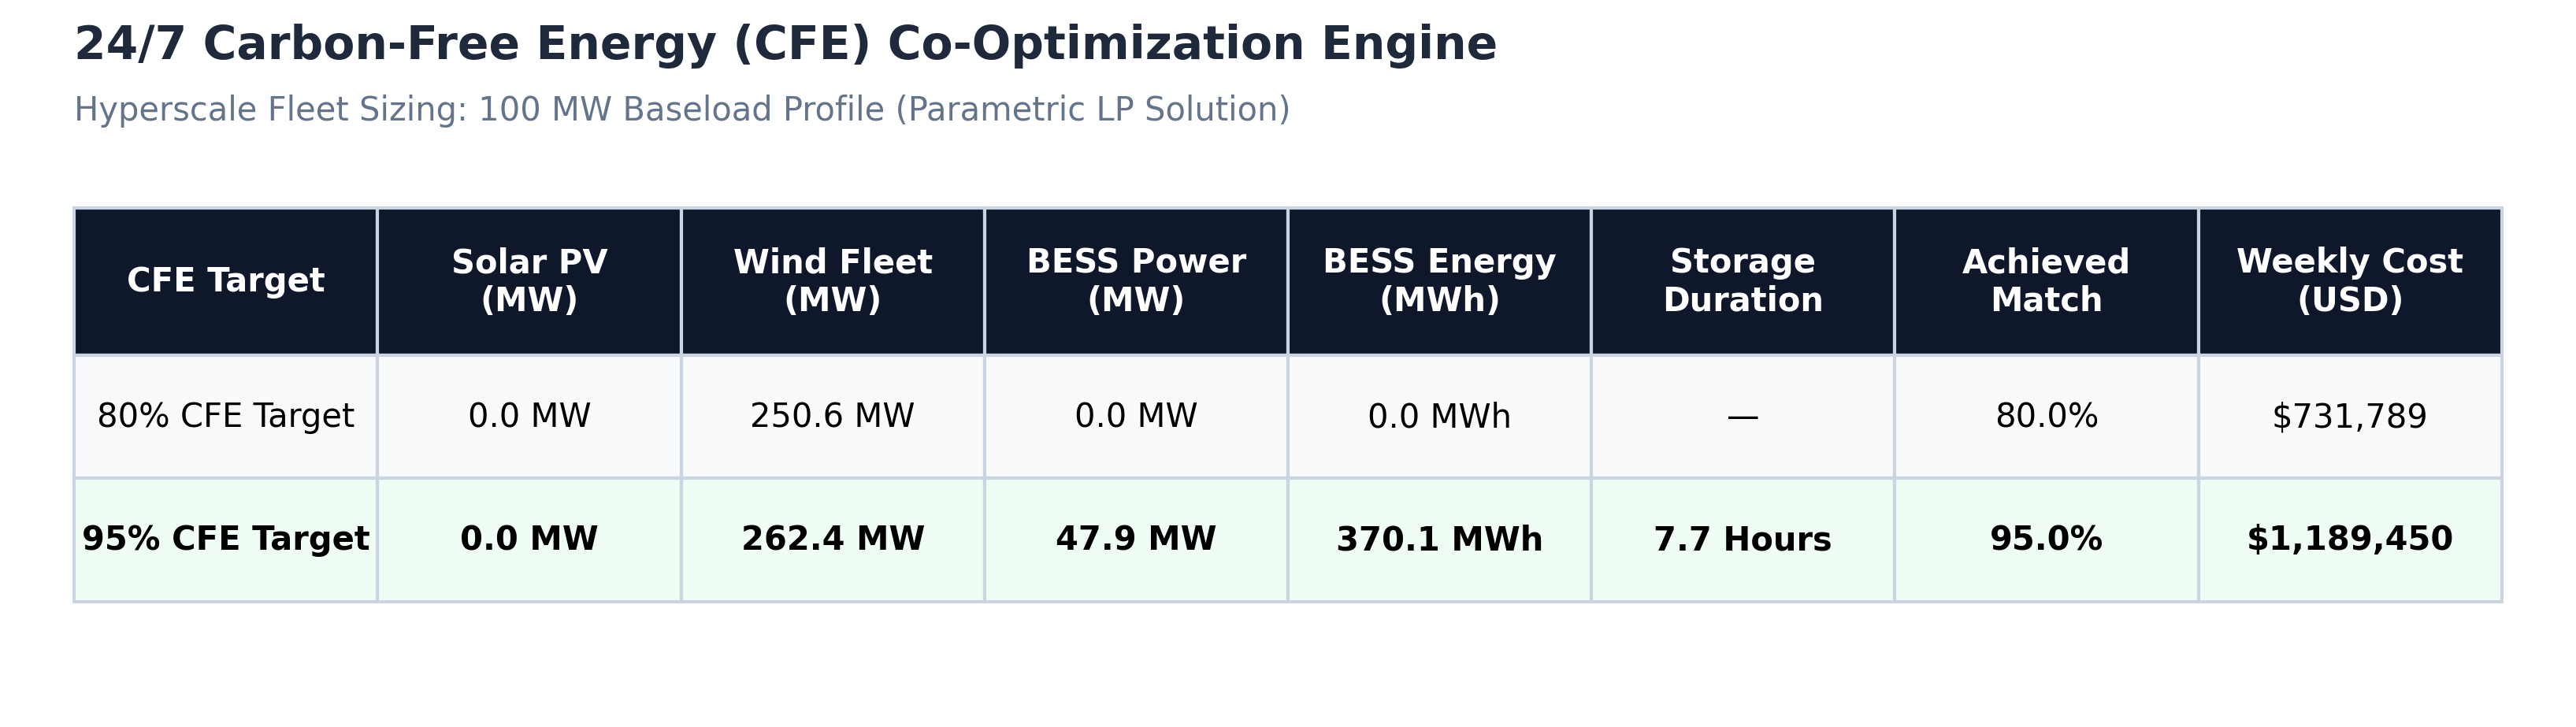

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt

# 1. Define summary data from optimization runs
columns = ["CFE Target", "Solar PV\n(MW)", "Wind Fleet\n(MW)", "BESS Power\n(MW)", "BESS Energy\n(MWh)", "Storage\nDuration", "Achieved\nMatch", "Weekly Cost\n(USD)"]
rows = [
    ["80% CFE Target", "0.0 MW", "250.6 MW", "0.0 MW", "0.0 MWh", "—", "80.0%", "$731,789"],
    ["95% CFE Target", "0.0 MW", "262.4 MW", "47.9 MW", "370.1 MWh", "7.7 Hours", "95.0%", "$1,189,450"]
]

# 2. Render as a publication-ready graphic
fig, ax = plt.subplots(figsize=(11, 3.2), dpi=300)
ax.axis('off')

# Title & subtitle
plt.text(0.02, 0.95, "24/7 Carbon-Free Energy (CFE) Co-Optimization Engine", fontsize=14, weight='bold', color='#1e293b')
plt.text(0.02, 0.86, "Hyperscale Fleet Sizing: 100 MW Baseload Profile (Parametric LP Solution)", fontsize=10, color='#64748b')

# Draw table
table = ax.table(
    cellText=rows,
    colLabels=columns,
    cellLoc='center',
    loc='center',
    bbox=[0.02, 0.15, 0.96, 0.58]
)

table.auto_set_font_size(False)
table.set_fontsize(10)

# Apply corporate styling
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('#cbd5e1')
    cell.set_linewidth(1.0)
    if row == 0:
        cell.set_facecolor('#0f172a')
        cell.get_text().set_color('white')
        cell.get_text().set_weight('bold')
        cell.set_height(0.24)
    elif row == 1:
        cell.set_facecolor('#f8fafc')
        cell.set_height(0.20)
    elif row == 2:
        cell.set_facecolor('#f0fdf4')  # Subtle green highlight for 95% target
        cell.get_text().set_weight('semibold')
        cell.set_height(0.20)

plt.tight_layout()

# Save high-resolution PNG
filename = "cfe_optimization_results.png"
plt.savefig(filename, bbox_inches='tight', dpi=300, facecolor='white')
plt.show()

# Trigger direct download to your phone
from google.colab import files
files.download(filename)

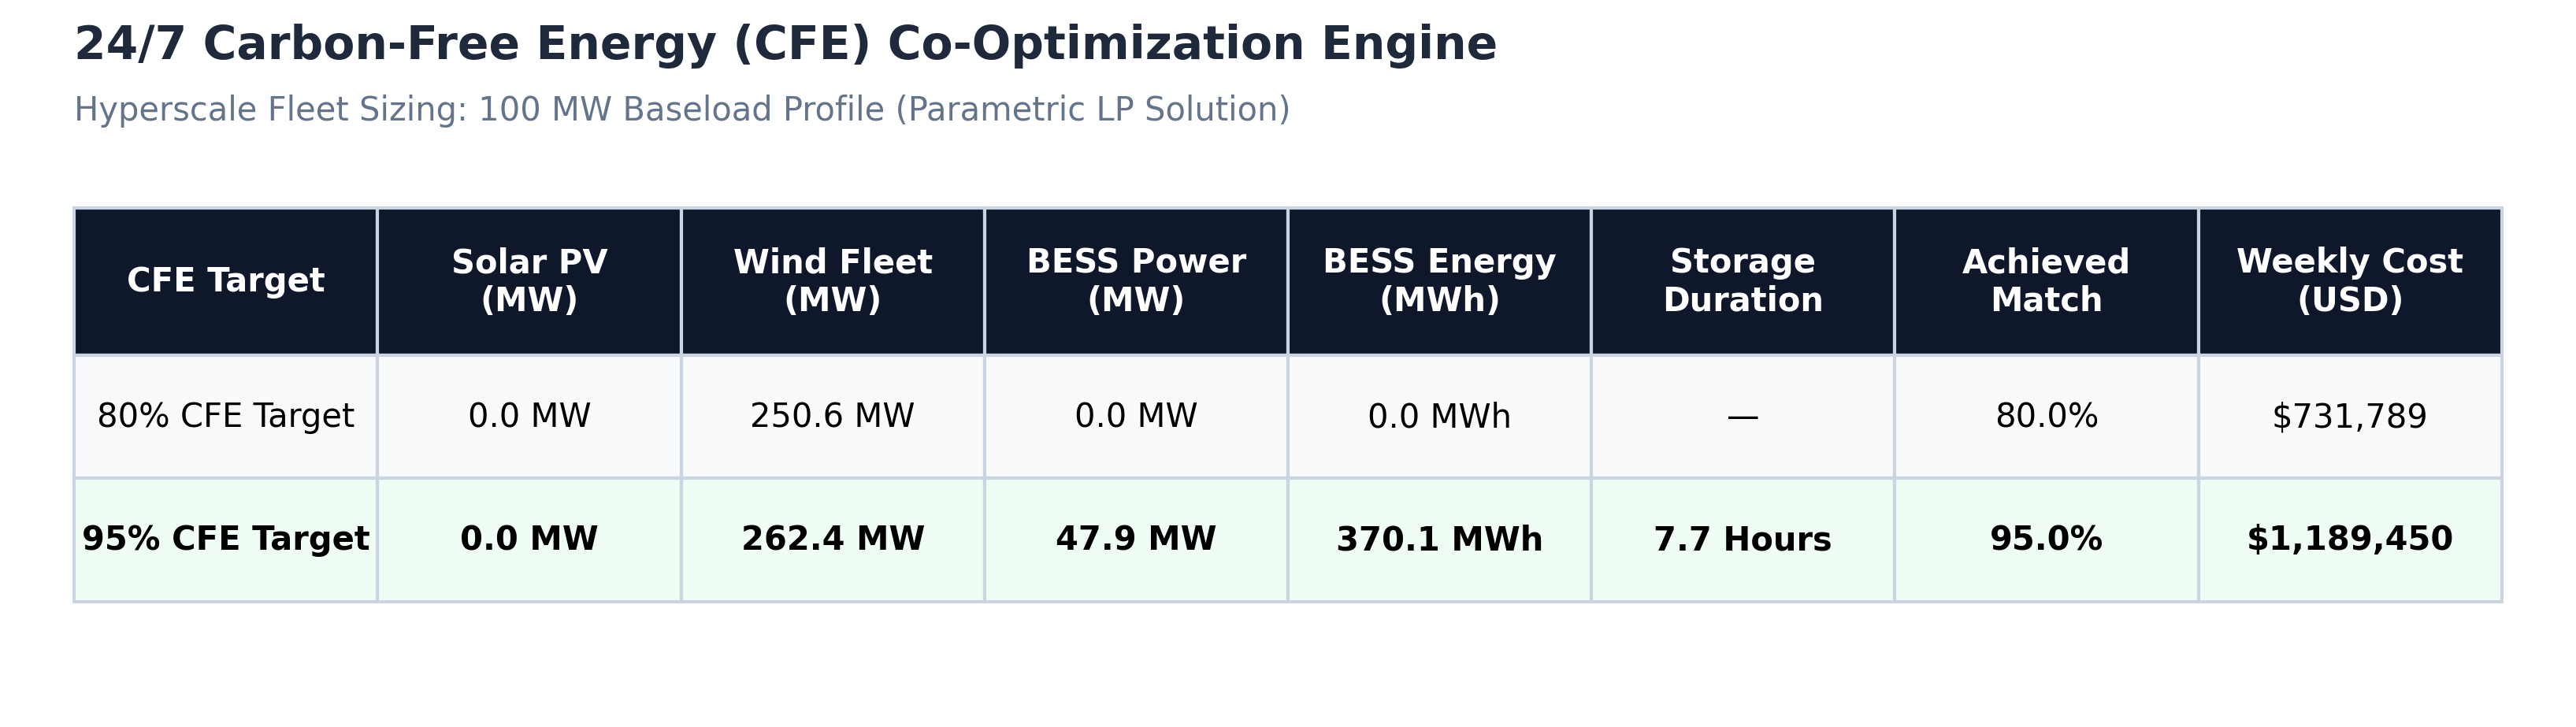

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files

# 1. Define summary data from optimization runs
columns = [
    "CFE Target", "Solar PV\n(MW)", "Wind Fleet\n(MW)",
    "BESS Power\n(MW)", "BESS Energy\n(MWh)", "Storage\nDuration",
    "Achieved\nMatch", "Weekly Cost\n(USD)"
]
rows = [
    ["80% CFE Target", "0.0 MW", "250.6 MW", "0.0 MW", "0.0 MWh", "—", "80.0%", "$731,789"],
    ["95% CFE Target", "0.0 MW", "262.4 MW", "47.9 MW", "370.1 MWh", "7.7 Hours", "95.0%", "$1,189,450"]
]

# 2. Render as a graphic
fig, ax = plt.subplots(figsize=(11, 3.2), dpi=300)
ax.axis('off')

# Title & subtitle
plt.text(0.02, 0.95, "24/7 Carbon-Free Energy (CFE) Co-Optimization Engine", fontsize=14, weight='bold', color='#1e293b')
plt.text(0.02, 0.86, "Hyperscale Fleet Sizing: 100 MW Baseload Profile (Parametric LP Solution)", fontsize=10, color='#64748b')

# Draw table
table = ax.table(
    cellText=rows,
    colLabels=columns,
    cellLoc='center',
    loc='center',
    bbox=[0.02, 0.15, 0.96, 0.58]
)

table.auto_set_font_size(False)
table.set_fontsize(10)

# Apply corporate styling
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('#cbd5e1')
    cell.set_linewidth(1.0)
    if row == 0:
        cell.set_facecolor('#0f172a')
        cell.get_text().set_color('white')
        cell.get_text().set_weight('bold')
        cell.set_height(0.24)
    elif row == 1:
        cell.set_facecolor('#f8fafc')
        cell.set_height(0.20)
    elif row == 2:
        cell.set_facecolor('#f0fdf4')
        cell.get_text().set_weight('semibold')
        cell.set_height(0.20)

plt.tight_layout()

# Save explicitly as .jpg
filename_jpg = "cfe_optimization_results.jpg"
plt.savefig(filename_jpg, format='jpg', dpi=300, facecolor='white', pil_kwargs={'quality': 95})
plt.show()

# Download .jpg directly to your mobile device
files.download(filename_jpg)